# PredictiveMaint AI — Endüstriyel Ekipman Arızası Tahmini

**Eğitim:** Makine ve Derin Öğrenme Uygulamaları · **Yazar:** Tugay Sinan Ergün (GitHub: TCoderr)

## 1. Problem tanımı
- **Girdi:** Freze tezgâhı benzeri bir sürecin ürün tipi (L/M/H), hava ve süreç sıcaklığı, devir, tork ve takım aşınması ölçümleri.
- **Çıktı:** Sürecin arızayla sonuçlanıp sonuçlanmayacağı (`Machine failure` = 1/0). Problem türü ikili sınıflandırmadır.
- **Gerçek dünya ihtiyacı:** Arızayı önceden tahmin etmek, plansız duruşları ve hasarı azaltmak için bakımın zamanında yapılmasını sağlar.
- **Yanlış negatiflerin önemi:** Yanlış negatif, kaçırılan gerçek bir arızadır. Bu nedenle yalnızca accuracy değil, özellikle **recall** önemlidir.

> **Önemli:** AI4I 2020 veri seti **sentetiktir**. UCI açıklamasına göre gerçek kestirimci bakım verisini yansıtmak için üretilmiştir; gerçek bir fabrikadan ölçülmemiştir. Bu çalışma akademik bir prototiptir. Sonuçlar gerçek fabrikalarda doğrudan güvenilir şekilde kullanılabilir değildir.

## 2. Kurulum ve veri
Notebook önce yerel `data/raw/ai4i2020.zip` dosyasını arar. Bulamazsa (ör. Colab) veriyi resmî UCI adresinden indirir.

In [1]:
import io, json, urllib.request, zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, confusion_matrix,
                             roc_auc_score, average_precision_score, precision_recall_curve, ConfusionMatrixDisplay)

SEED = 42
UCI_ZIP = 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip'
local = next((p for p in [Path('data/raw/ai4i2020.zip'), Path('../data/raw/ai4i2020.zip')] if p.exists()), None)
raw = local.read_bytes() if local else urllib.request.urlopen(UCI_ZIP, timeout=60).read()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    df = pd.read_csv(z.open('ai4i2020.csv'), encoding='utf-8-sig')
print('Kaynak:', local if local else UCI_ZIP)
OUT = Path('reports') if Path('reports').exists() else (Path('../reports') if Path('../reports').exists() else Path('outputs'))
FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
R = {}   # bütün sayısal sonuçlar buraya yazılır ve sonda metrics.json olarak kaydedilir

Kaynak: data\raw\ai4i2020.zip


## 3. Veri setinin tanıtılması

In [2]:
print('shape:', df.shape)
print(df.dtypes)
df.head()

shape: (10000, 14)
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
TARGET = 'Machine failure'
MODES = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
missing = int(df.isnull().sum().sum()); dup = int(df.duplicated().sum())
counts = df[TARGET].value_counts().sort_index()
any_mode = df[MODES].max(axis=1)
R['data'] = {'rows': int(df.shape[0]), 'cols': int(df.shape[1]), 'missing': missing, 'duplicates': dup,
             'failures': int(counts[1]), 'non_failures': int(counts[0]), 'failure_rate': float(counts[1] / len(df)),
             'mode_counts': {m: int(df[m].sum()) for m in MODES},
             'failure_without_mode': int(((df[TARGET] == 1) & (any_mode == 0)).sum()),
             'mode_without_failure': int(((df[TARGET] == 0) & (any_mode == 1)).sum()),
             'mode_without_failure_by_mode': {m: int(((df[TARGET] == 0) & (df[m] == 1)).sum()) for m in MODES},
             'type_counts': {k: int(v) for k, v in df['Type'].value_counts().items()}}
print(json.dumps(R['data'], indent=2))
print(f"Sınıf dengesizliği: arıza oranı %{100 * R['data']['failure_rate']:.2f} (yaklaşık 1/{round(1 / R['data']['failure_rate'])})")

{
  "rows": 10000,
  "cols": 14,
  "missing": 0,
  "duplicates": 0,
  "failures": 339,
  "non_failures": 9661,
  "failure_rate": 0.0339,
  "mode_counts": {
    "TWF": 46,
    "HDF": 115,
    "PWF": 95,
    "OSF": 98,
    "RNF": 19
  },
  "failure_without_mode": 9,
  "mode_without_failure": 18,
  "mode_without_failure_by_mode": {
    "TWF": 0,
    "HDF": 0,
    "PWF": 0,
    "OSF": 0,
    "RNF": 18
  },
  "type_counts": {
    "L": 6000,
    "M": 2997,
    "H": 1003
  }
}
Sınıf dengesizliği: arıza oranı %3.39 (yaklaşık 1/29)


**Gözlem:**
- Eksik değer yoktur.
- Hedef sınıf çok dengesizdir.
- Arıza türü sütunları (TWF…RNF) hedefle tam tutarlı değildir: bazı arızaların hiçbir türü yoktur, bazı türler ise `Machine failure` = 0 olan satırlarda görülür. Kesin sayılar yukarıdadır.
- Bu sütunlar arıza **gerçekleştikten sonra** bilinebilecek bilgilerdir. Modele girdi olarak verilirse hedef sızıntısı olur; bu nedenle **modelde kullanılmaz**, yalnızca hata analizinde kullanılır.
- `UDI` (sıra numarası) ve `Product ID` (ürün kimliği) de tahmin için anlamlı değildir. `Product ID`'nin ilk harfi `Type` ile aynıdır, kalanı seri numarasıdır. İkisi de modele alınmaz.

In [4]:
pid_letter_matches_type = bool((df['Product ID'].str[0] == df['Type']).all())
print('Product ID ilk harfi == Type :', pid_letter_matches_type)
print('UDI benzersiz mi:', df['UDI'].is_unique)
R['data']['product_id_letter_equals_type'] = pid_letter_matches_type

Product ID ilk harfi == Type : True
UDI benzersiz mi: True


## 4. Veri keşfi (EDA)
### Görsel 1 — Sınıf dağılımı ve arıza türleri

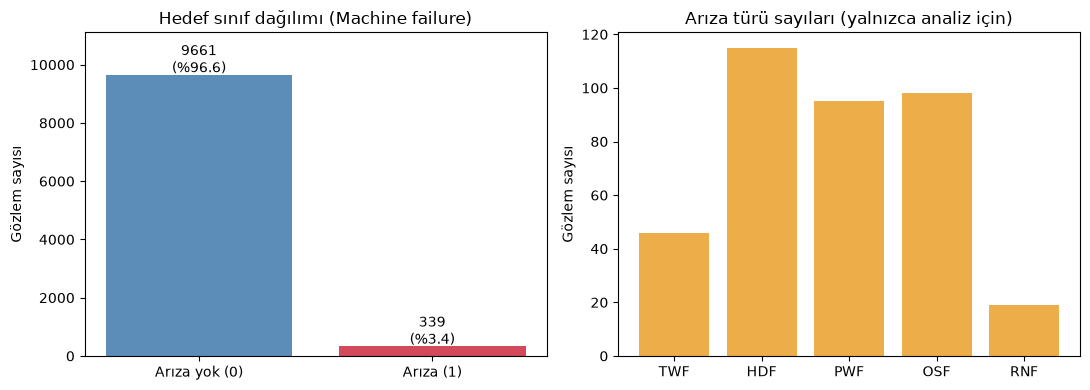

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(['Arıza yok (0)', 'Arıza (1)'], counts.values, color=['#5B8DB8', '#D1495B'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 80, f'{v}\n(%{100 * v / len(df):.1f})', ha='center')
axes[0].set_title('Hedef sınıf dağılımı (Machine failure)'); axes[0].set_ylabel('Gözlem sayısı'); axes[0].set_ylim(0, counts.max() * 1.15)
mc = pd.Series(R['data']['mode_counts'])
axes[1].bar(mc.index, mc.values, color='#EDAE49')
axes[1].set_title('Arıza türü sayıları (yalnızca analiz için)'); axes[1].set_ylabel('Gözlem sayısı')
fig.tight_layout(); fig.savefig(FIG / '01_sinif_dagilimi.png', dpi=150); plt.show()

**Yorum:** 10.000 süreçten yalnızca küçük bir kısmı arızalıdır. Her zaman "arıza yok" diyen bir model bile çok yüksek accuracy elde eder. Bu nedenle accuracy tek başına yanıltıcıdır (bkz. Bölüm 7).

### Görsel 2 — Sensör ve ekipman özelliklerinin dağılımı (sınıfa göre)

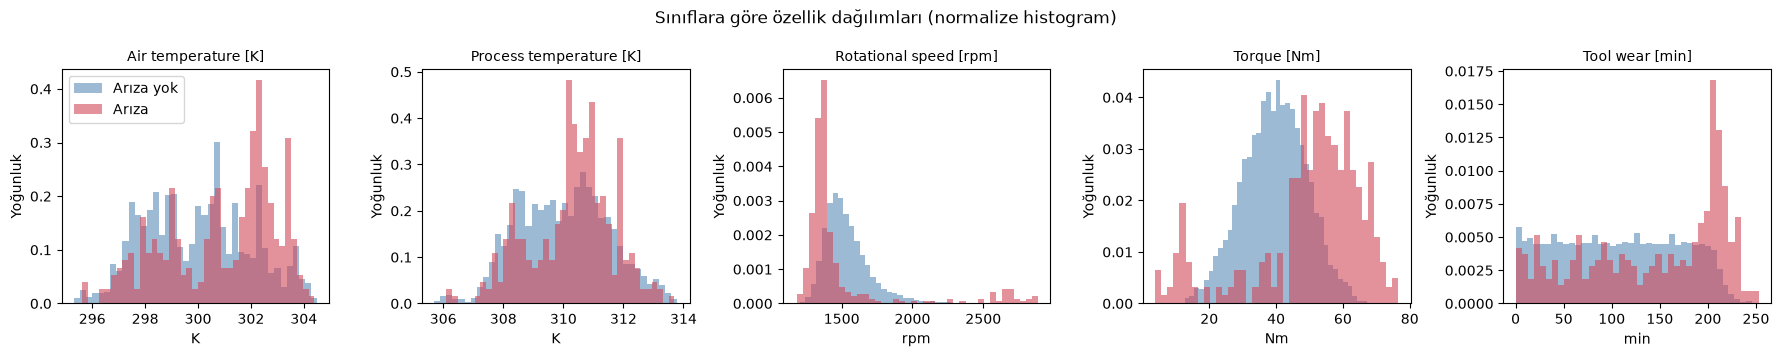

                 Air temperature [K]  Process temperature [K]  \
Machine failure                                                 
0                             299.97                   310.00   
1                             300.89                   310.29   

                 Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Machine failure                                                        
0                               1540.26        39.63           106.69  
1                               1496.49        50.17           143.78  


In [6]:
NUM = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, c in zip(axes, NUM):
    ax.hist(df.loc[df[TARGET] == 0, c], bins=40, density=True, alpha=0.6, label='Arıza yok', color='#5B8DB8')
    ax.hist(df.loc[df[TARGET] == 1, c], bins=40, density=True, alpha=0.6, label='Arıza', color='#D1495B')
    ax.set_title(c, fontsize=10); ax.set_xlabel(c.split(' [')[-1].rstrip(']')); ax.set_ylabel('Yoğunluk')
axes[0].legend()
fig.suptitle('Sınıflara göre özellik dağılımları (normalize histogram)'); fig.tight_layout(); fig.savefig(FIG / '02_ozellik_dagilimlari.png', dpi=150); plt.show()
print(df.groupby(TARGET)[NUM].mean().round(2))

**Yorum:** Arızalı süreçlerde tork ve takım aşınması belirgin biçimde daha yüksektir; devir dağılımı iki uca yayılır. Sıcaklıkların sınıflar arasındaki farkı daha küçüktür.

### Görsel 3 — Arızayla ilişkili özellikler: tork–devir düzlemi ve ürün tipine göre arıza oranı

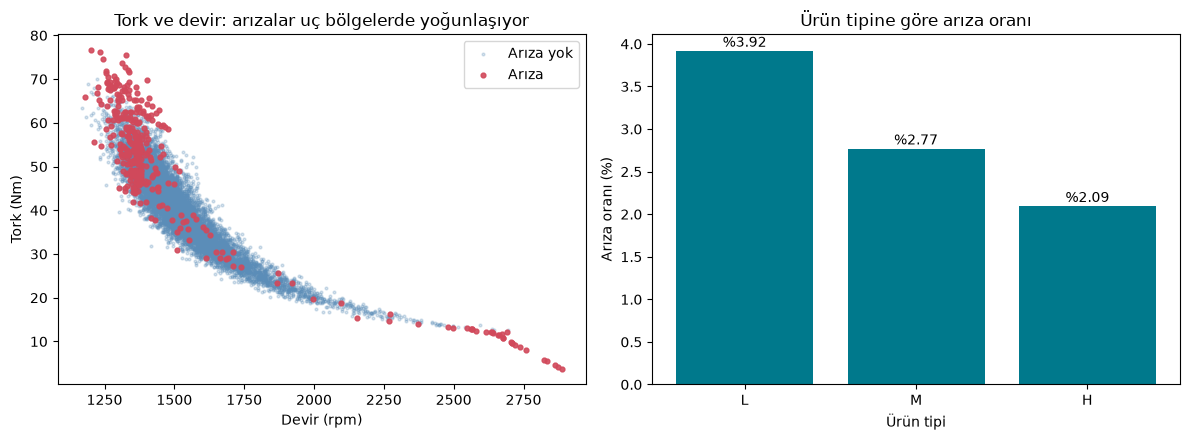

Type
L    3.917
M    2.769
H    2.094
Name: Machine failure, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ok, bad = df[df[TARGET] == 0], df[df[TARGET] == 1]
axes[0].scatter(ok['Rotational speed [rpm]'], ok['Torque [Nm]'], s=4, alpha=0.25, color='#5B8DB8', label='Arıza yok')
axes[0].scatter(bad['Rotational speed [rpm]'], bad['Torque [Nm]'], s=12, alpha=0.9, color='#D1495B', label='Arıza')
axes[0].set_xlabel('Devir (rpm)'); axes[0].set_ylabel('Tork (Nm)'); axes[0].set_title('Tork ve devir: arızalar uç bölgelerde yoğunlaşıyor'); axes[0].legend()
rate = df.groupby('Type')[TARGET].mean().reindex(['L', 'M', 'H']) * 100
axes[1].bar(rate.index, rate.values, color='#00798C')
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.05, f'%{v:.2f}', ha='center')
axes[1].set_title('Ürün tipine göre arıza oranı'); axes[1].set_xlabel('Ürün tipi'); axes[1].set_ylabel('Arıza oranı (%)')
fig.tight_layout(); fig.savefig(FIG / '03_arizayla_iliskili.png', dpi=150); plt.show()
R['data']['failure_rate_by_type'] = {k: float(v) for k, v in rate.items()}
print(rate.round(3))

### Görsel 4 — Korelasyon matrisi

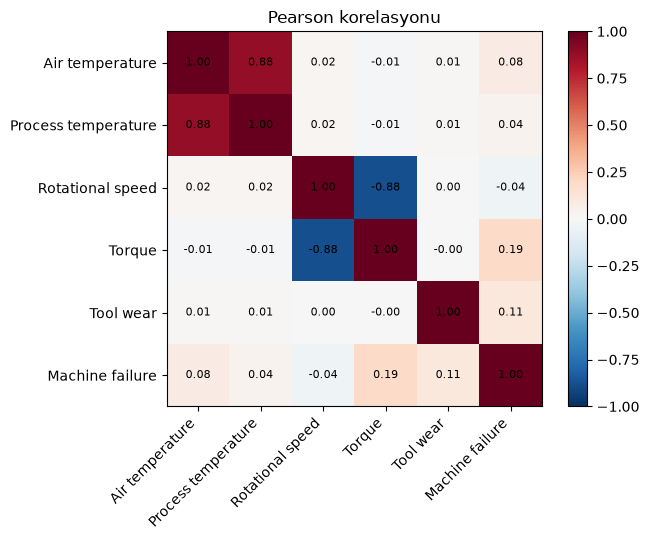

In [8]:
corr = df[NUM + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
labels = [c.split(' [')[0] for c in corr.columns]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right'); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); ax.set_title('Pearson korelasyonu'); fig.tight_layout(); fig.savefig(FIG / '04_korelasyon.png', dpi=150); plt.show()

**Yorum:** Hava ve süreç sıcaklığı güçlü biçimde ilişkilidir. Devir ile tork güçlü negatif ilişkilidir. Hedefle doğrusal korelasyonlar zayıftır; arıza, tek bir değişkenin doğrusal etkisiyle değil, değişkenlerin uç kombinasyonlarıyla ilişkilidir.

## 5. Veri ön işleme

1. **Eksik değer:** Yoktur (yukarıda kontrol edildi).
2. **Aykırı değer:** IQR kuralıyla sayıldı. Değerler fiziksel olarak makul olduğu ve arızalar tam da uç bölgelerde yoğunlaştığı için **silinmedi**.
3. **Türetilmiş özellikler:**
   - `temp_diff` = süreç sıcaklığı − hava sıcaklığı
   - `power_w` = tork × devir × 2π/60
   - `strain` = takım aşınması × tork

   Hepsi aynı andaki sensör değerlerinden hesaplanır; gelecekteki veya arıza sonrasındaki bilgiyi kullanmaz. UCI açıklamasındaki arıza mekanizmalarıyla (ısı dağılımı, güç, aşırı zorlanma) ilişkilidirler. Not: Sentetik veri bu kurallarla üretildiği için bu özellikler gerçek veride bu kadar güçlü olmayabilir.
4. **Kategorik encoding:** `Type` (L/M/H) one-hot kodlanır.
5. **Ölçekleme:** Sayısal özelliklere `StandardScaler` uygulanır.
6. **Bölme:** Katmanlı (stratified) %60 eğitim / %20 doğrulama / %20 test, `random_state=42`.
7. **Sızıntı kontrolü:** Bütün dönüşümler `Pipeline` içinde yalnızca eğitim verisine `fit` edilir. Doğrulama ve test verisine yalnızca `transform` uygulanır. Hiperparametre ve eşik seçimi doğrulama verisiyle yapılır; test verisi sonda bir kez kullanılır.

In [9]:
q1, q3 = df[NUM].quantile(0.25), df[NUM].quantile(0.75); iqr = q3 - q1
outliers = ((df[NUM] < q1 - 1.5 * iqr) | (df[NUM] > q3 + 1.5 * iqr)).sum()
R['outliers_iqr'] = {k: int(v) for k, v in outliers.items()}
print('IQR aykırı değer sayıları:'); print(outliers)

data = df.copy()
data['temp_diff'] = data['Process temperature [K]'] - data['Air temperature [K]']
data['power_w'] = data['Torque [Nm]'] * data['Rotational speed [rpm]'] * 2 * np.pi / 60
data['strain'] = data['Tool wear [min]'] * data['Torque [Nm]']
BASE = NUM + ['Type']
ENG = NUM + ['temp_diff', 'power_w', 'strain', 'Type']
LEAKY = ['UDI', 'Product ID', TARGET] + MODES
assert not set(LEAKY) & set(ENG), 'sızıntı: yasaklı sütun özelliklerde'
X, y = data[ENG], data[TARGET]
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
assert not (set(X_train.index) & set(X_val.index) | set(X_train.index) & set(X_test.index) | set(X_val.index) & set(X_test.index))
R['split'] = {n: {'rows': int(len(a)), 'failures': int(b.sum()), 'failure_rate': float(b.mean())}
              for n, a, b in (('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test))}
print(json.dumps(R['split'], indent=2))

def make_pre(cols):
    num = [c for c in cols if c != 'Type']
    return ColumnTransformer([('num', StandardScaler(), num), ('cat', OneHotEncoder(handle_unknown='ignore'), ['Type'])])

IQR aykırı değer sayıları:
Air temperature [K]          0
Process temperature [K]      0
Rotational speed [rpm]     418
Torque [Nm]                 69
Tool wear [min]              0
dtype: int64
{
  "train": {
    "rows": 6000,
    "failures": 203,
    "failure_rate": 0.03383333333333333
  },
  "val": {
    "rows": 2000,
    "failures": 68,
    "failure_rate": 0.034
  },
  "test": {
    "rows": 2000,
    "failures": 68,
    "failure_rate": 0.034
  }
}


## 6. Modeller ve eğitim

| Model | Özellikler | Neden? |
|---|---|---|
| Logistic Regression (temel) | 5 sensör + Type | Yorumlanabilir **başlangıç modeli** |
| Logistic Regression (+türetilmiş) | + temp_diff, power_w, strain | Alan bilgisinin doğrusal modele katkısını görmek için |
| Random Forest | türetilmiş özellikler dahil | Doğrusal olmayan eşik ilişkilerini yakalayabilen **karşılaştırma modeli** |
| MLPClassifier | türetilmiş özellikler dahil | Küçük bir sinir ağı; GPU veya PyTorch gerektirmez |

Her model için küçük bir hiperparametre ızgarası **eğitim verisinde eğitilir** ve **doğrulama PR-AUC** değerine göre seçilir. PR-AUC, dengesiz veride pozitif sınıfa odaklandığı için ROC-AUC'den daha bilgilendiricidir. Test verisi bu aşamada **kullanılmaz**.

In [10]:
from itertools import product
CANDIDATES = {
    'LogReg (temel)': (BASE, lambda p: LogisticRegression(max_iter=3000, C=p[0], class_weight=p[1]),
                       list(product([0.01, 0.1, 1.0, 10.0], [None, 'balanced'])), ('C', 'class_weight')),
    'LogReg (+türetilmiş)': (ENG, lambda p: LogisticRegression(max_iter=3000, C=p[0], class_weight=p[1]),
                             list(product([0.01, 0.1, 1.0, 10.0], [None, 'balanced'])), ('C', 'class_weight')),
    'Random Forest': (ENG, lambda p: RandomForestClassifier(n_estimators=300, max_depth=p[0], min_samples_leaf=p[1], class_weight=p[2],
                                                             n_jobs=-1, random_state=SEED),
                      list(product([None, 12], [1, 3], [None, 'balanced_subsample'])), ('max_depth', 'min_samples_leaf', 'class_weight')),
    'MLP': (ENG, lambda p: MLPClassifier(hidden_layer_sizes=p[0], alpha=p[1], max_iter=600, early_stopping=True,
                                         validation_fraction=0.15, random_state=SEED),
            list(product([(32, 16), (64, 32)], [1e-4, 1e-3])), ('hidden_layer_sizes', 'alpha')),
}
best = {}; R['tuning'] = {}
t0 = time.time()
for name, (cols, build, grid, pnames) in CANDIDATES.items():
    trials = []
    for p in grid:
        pipe = Pipeline([('pre', make_pre(cols)), ('model', build(p))]).fit(X_train[cols], y_train)   # fit: yalnızca eğitim
        ap = average_precision_score(y_val, pipe.predict_proba(X_val[cols])[:, 1])                       # seçim: doğrulama
        trials.append((ap, p, pipe))
    ap, p, pipe = max(trials, key=lambda t: t[0])
    best[name] = (cols, pipe)
    R['tuning'][name] = {'features': cols, 'grid_size': len(grid), 'best_params': {k: str(v) for k, v in zip(pnames, p)}, 'val_pr_auc': float(ap)}
    print(f'{name:22s} en iyi {dict(zip(pnames, p))}  doğrulama PR-AUC = {ap:.4f}  ({len(grid)} deneme)')
R['training_seconds'] = round(time.time() - t0, 1)
# sızıntı kontrolü: ölçekleyicinin ortalamaları eğitim verisinin ortalamalarıdır
sc = best['Random Forest'][1].named_steps['pre'].named_transformers_['num']
assert np.allclose(sc.mean_, X_train[[c for c in ENG if c != 'Type']].mean().values), 'scaler eğitim dışı veriyle fit edilmiş!'
print('Ölçekleyici yalnızca eğitim verisiyle fit edildi: doğrulandı.')

LogReg (temel)         en iyi {'C': 1.0, 'class_weight': None}  doğrulama PR-AUC = 0.4054  (8 deneme)


LogReg (+türetilmiş)   en iyi {'C': 1.0, 'class_weight': None}  doğrulama PR-AUC = 0.4725  (8 deneme)


Random Forest          en iyi {'max_depth': 12, 'min_samples_leaf': 1, 'class_weight': None}  doğrulama PR-AUC = 0.8668  (8 deneme)


MLP                    en iyi {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}  doğrulama PR-AUC = 0.7231  (4 deneme)
Ölçekleyici yalnızca eğitim verisiyle fit edildi: doğrulandı.


## 7. Değerlendirme

Önce bütün modeller test kümesinde **varsayılan 0,5 eşiğiyle** değerlendirilir. Final model, **doğrulama** PR-AUC değeri en yüksek olan modeldir; seçimde test sonuçları kullanılmaz. Karşılaştırma için bir de "her zaman arıza yok" diyen naif model eklenir.

In [11]:
def evaluate(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred), 'f1': f1_score(y_true, pred), 'f2': fbeta_score(y_true, pred, beta=2),
            'roc_auc': roc_auc_score(y_true, proba), 'pr_auc': average_precision_score(y_true, proba),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp), 'fnr': fn / (fn + tp), 'threshold': thr}

R['test_default'] = {}
proba_test = {}
for name, (cols, pipe) in best.items():
    proba_test[name] = pipe.predict_proba(X_test[cols])[:, 1]
    R['test_default'][name] = {k: float(v) for k, v in evaluate(y_test, proba_test[name]).items()}
naive = np.zeros(len(y_test))
R['naive_all_zero'] = {'accuracy': float(accuracy_score(y_test, naive)), 'recall': 0.0, 'fn': int(y_test.sum())}
table = pd.DataFrame(R['test_default']).T[['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'tp', 'fn', 'fp']]
table['val_pr_auc'] = [R['tuning'][n]['val_pr_auc'] for n in table.index]
print(f"Naif model ('hep arıza yok') test accuracy: {R['naive_all_zero']['accuracy']:.4f}, recall: 0, kaçırılan arıza: {R['naive_all_zero']['fn']}")
table.round(4)

Naif model ('hep arıza yok') test accuracy: 0.9660, recall: 0, kaçırılan arıza: 68


,accuracy,precision,recall,f1,roc_auc,pr_auc,tp,fn,fp,val_pr_auc
LogReg (temel),0.9685,0.6923,0.1324,0.2222,0.9003,0.4164,9.0,59.0,4.0,0.4054
LogReg (+türetilmiş),0.9675,0.5714,0.1765,0.2697,0.9197,0.4643,12.0,56.0,9.0,0.4725
Random Forest,0.9920,0.9815,0.7794,0.8689,0.9791,0.8910,53.0,15.0,1.0,0.8668
MLP,0.9790,0.7097,0.6471,0.6769,0.9729,0.7408,44.0,24.0,18.0,0.7231


Doğrulama PR-AUC değerine göre seçilen model: Random Forest


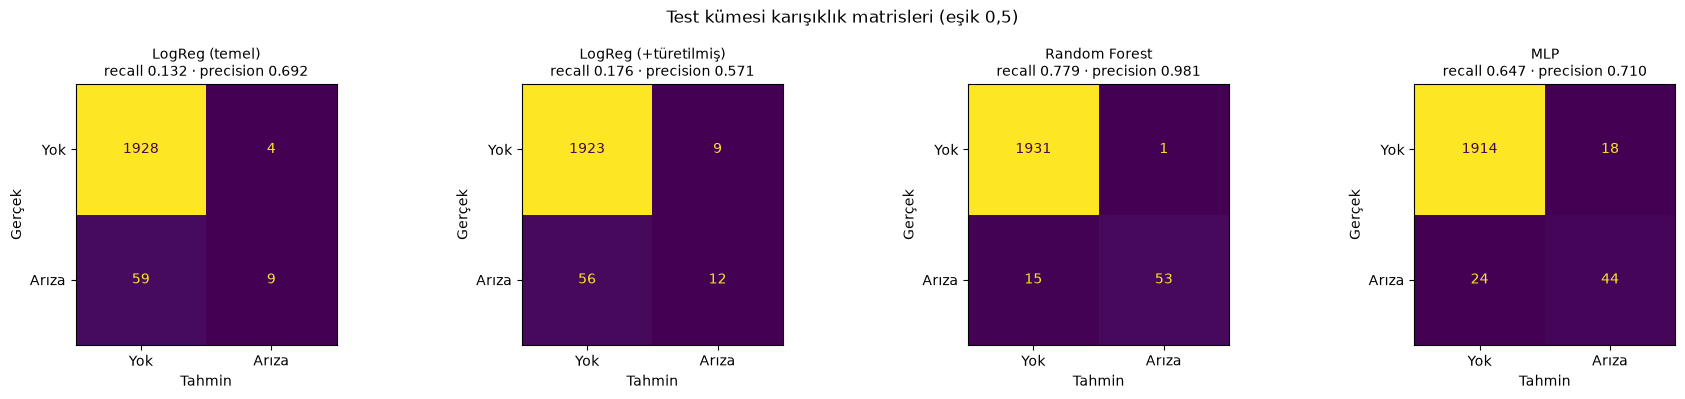

In [12]:
SELECTED = max(R['tuning'], key=lambda n: R['tuning'][n]['val_pr_auc'])
R['selected_model'] = SELECTED
print('Doğrulama PR-AUC değerine göre seçilen model:', SELECTED)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, best):
    m = R['test_default'][name]
    ConfusionMatrixDisplay(np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]], dtype=int), display_labels=['Yok', 'Arıza']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(f"{name}\nrecall {m['recall']:.3f} · precision {m['precision']:.3f}", fontsize=10)
    ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
fig.suptitle('Test kümesi karışıklık matrisleri (eşik 0,5)'); fig.tight_layout(); fig.savefig(FIG / '05_karisiklik_matrisleri.png', dpi=150); plt.show()

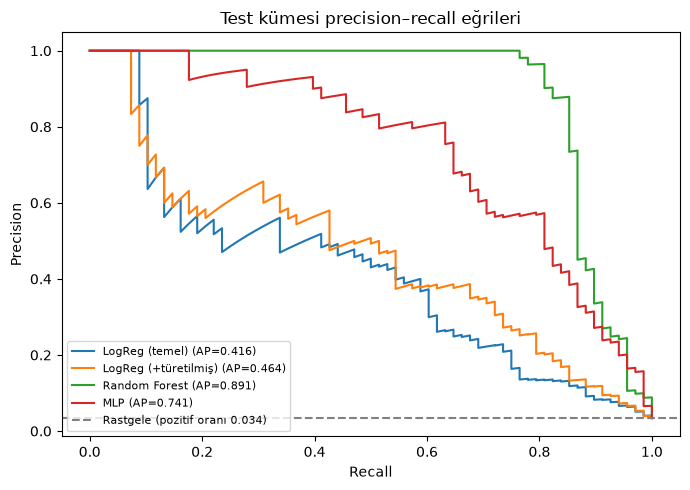

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in proba_test.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, label=f"{name} (AP={R['test_default'][name]['pr_auc']:.3f})")
ax.axhline(y_test.mean(), color='grey', linestyle='--', label=f'Rastgele (pozitif oranı {y_test.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Test kümesi precision–recall eğrileri'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '06_pr_egrileri.png', dpi=150); plt.show()

### Accuracy neden yeterli değil?
Test kümesinde her zaman "arıza yok" diyen naif model, hiçbir arızayı yakalamadığı hâlde yüksek accuracy alır (yukarıdaki çıktı). Bu nedenle dengesiz bir problemde accuracy, modelin arızaları yakalayıp yakalamadığını göstermez. Asıl soru şudur: **Gerçek arızaların ne kadarı yakalandı (recall) ve verilen alarmların ne kadarı doğru (precision)?**

## 8. Yanlış negatifler ve karar eşiği

Seçilen modelin karar eşiği **yalnızca doğrulama verisiyle** belirlenir. Ölçüt olarak **F2 skoru** kullanılır; F2, recall'a precision'dan iki kat ağırlık verir. Bakımda bir arızayı kaçırmak (FN), gereksiz bir kontrolden (FP) genellikle daha pahalıdır. Seçilen eşik test kümesinde **bir kez** uygulanır.

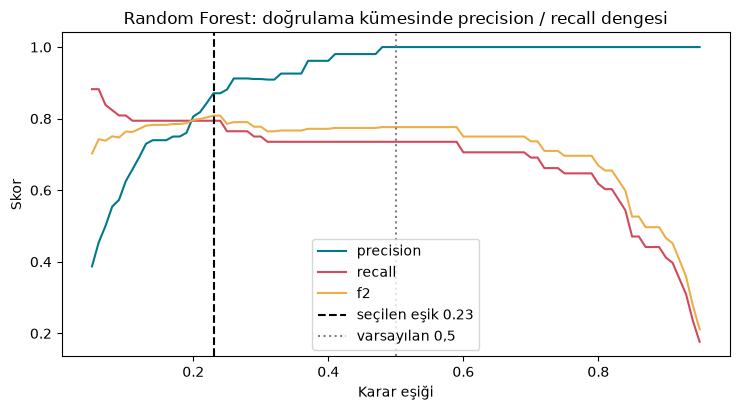

Seçilen eşik: 0.23 (doğrulama F2 maksimum)
Test, eşik 0,5  : TP 53, FN 15, FP 1 → recall 0.7794, precision 0.9815, FNR 0.2206
Test, eşik 0.23 : TP 58, FN 10, FP 8 → recall 0.8529, precision 0.8788, FNR 0.1471


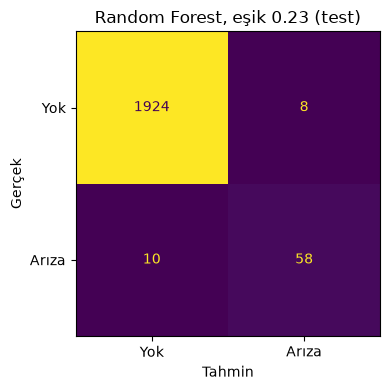

In [14]:
cols, pipe = best[SELECTED]
p_val = pipe.predict_proba(X_val[cols])[:, 1]
thrs = np.round(np.arange(0.05, 0.951, 0.01), 2)
curve = pd.DataFrame([{k: evaluate(y_val, p_val, t)[k] for k in ('precision', 'recall', 'f1', 'f2')} | {'threshold': t} for t in thrs])
best_thr = float(curve.loc[curve['f2'].idxmax(), 'threshold'])
R['threshold'] = {'criterion': 'max F2 on validation', 'value': best_thr,
                  'val_at_threshold': {k: float(v) for k, v in evaluate(y_val, p_val, best_thr).items()},
                  'val_at_0_5': {k: float(v) for k, v in evaluate(y_val, p_val, 0.5).items()}}
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, c in (('precision', '#00798C'), ('recall', '#D1495B'), ('f2', '#EDAE49')):
    ax.plot(curve.threshold, curve[k], label=k, color=c)
ax.axvline(best_thr, color='black', linestyle='--', label=f'seçilen eşik {best_thr:.2f}')
ax.axvline(0.5, color='grey', linestyle=':', label='varsayılan 0,5')
ax.set_xlabel('Karar eşiği'); ax.set_ylabel('Skor'); ax.set_title(f'{SELECTED}: doğrulama kümesinde precision / recall dengesi'); ax.legend()
fig.tight_layout(); fig.savefig(FIG / '07_esik_dengesi.png', dpi=150); plt.show()
final = evaluate(y_test, proba_test[SELECTED], best_thr)
R['test_final'] = {k: float(v) for k, v in final.items()}
d = R['test_default'][SELECTED]
print(f'Seçilen eşik: {best_thr:.2f} (doğrulama F2 maksimum)')
print(f"Test, eşik 0,5  : TP {d['tp']:.0f}, FN {d['fn']:.0f}, FP {d['fp']:.0f} → recall {d['recall']:.4f}, precision {d['precision']:.4f}, FNR {d['fnr']:.4f}")
print(f"Test, eşik {best_thr:.2f} : TP {final['tp']}, FN {final['fn']}, FP {final['fp']} → recall {final['recall']:.4f}, precision {final['precision']:.4f}, FNR {final['fnr']:.4f}")
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(np.array([[final['tn'], final['fp']], [final['fn'], final['tp']]]), display_labels=['Yok', 'Arıza']).plot(ax=ax, colorbar=False, values_format='d')
ax.set_title(f'{SELECTED}, eşik {best_thr:.2f} (test)'); ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek')
fig.tight_layout(); fig.savefig(FIG / '08_final_karisiklik.png', dpi=150); plt.show()

**Yanlış negatif oranı (FNR) = FN / (FN + TP) = 1 − recall.** Yani recall arttıkça kaçırılan arıza oranı aynı ölçüde azalır. Eşiği düşürmek recall'u artırır, ancak daha fazla yanlış alarm (FP) üretir ve precision düşer.

Hangi dengenin doğru olduğu, bir arızanın gerçek maliyetine bağlıdır. Bu çalışmada gerçek işletme maliyeti bilinmediği için **parasal maliyet hesabı yapılmamıştır**.

## 9. Açıklanabilirlik

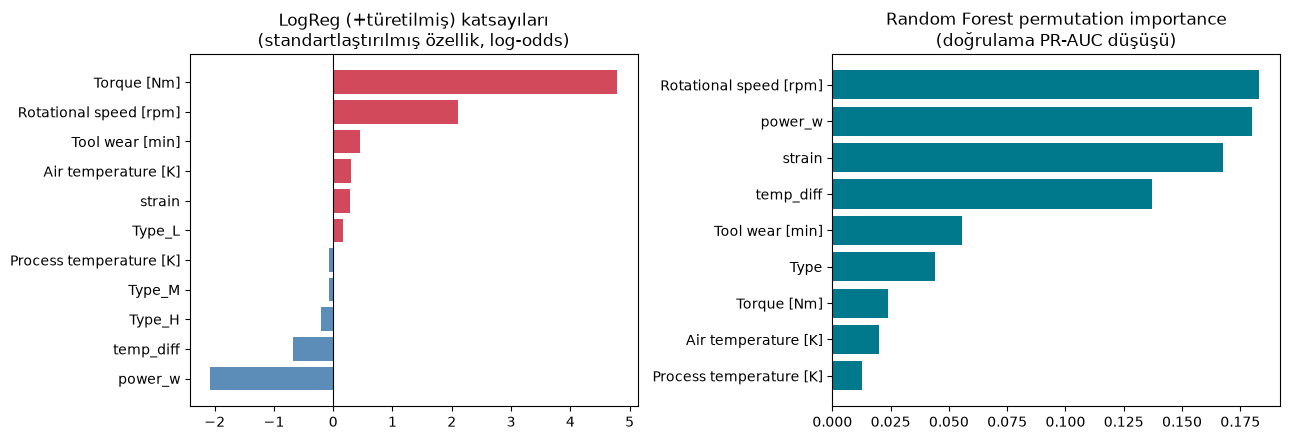

power_w                   -2.075
temp_diff                 -0.684
Type_H                    -0.200
Type_M                    -0.073
Process temperature [K]   -0.066
Type_L                     0.164
strain                     0.278
Air temperature [K]        0.295
Tool wear [min]            0.448
Rotational speed [rpm]     2.101
Torque [Nm]                4.790
dtype: float64
Process temperature [K]    0.0128
Air temperature [K]        0.0202
Torque [Nm]                0.0238
Type                       0.0441
Tool wear [min]            0.0555
temp_diff                  0.1373
strain                     0.1674
power_w                    0.1801
Rotational speed [rpm]     0.1829
dtype: float64


In [15]:
# Logistic Regression katsayıları: sayısal özellikler standartlaştırıldığı için katsayı = 1 standart sapmalık artışın log-odds etkisi
lr = best['LogReg (+türetilmiş)'][1]
names = lr.named_steps['pre'].get_feature_names_out()
coef = pd.Series(lr.named_steps['model'].coef_[0], index=[n.split('__')[1] for n in names]).sort_values()
# Random Forest: permutation importance, doğrulama verisinde PR-AUC düşüşü (impurity importance'a göre daha güvenilir)
rf_cols, rf = best['Random Forest']
pi = permutation_importance(rf, X_val[rf_cols], y_val, scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=rf_cols).sort_values()
R['explain'] = {'logreg_eng_coef': {k: float(v) for k, v in coef.items()}, 'rf_permutation_pr_auc_drop': {k: float(v) for k, v in perm.items()}}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(coef.index, coef.values, color=['#D1495B' if v > 0 else '#5B8DB8' for v in coef.values])
axes[0].set_title('LogReg (+türetilmiş) katsayıları\n(standartlaştırılmış özellik, log-odds)'); axes[0].axvline(0, color='black', linewidth=0.8)
axes[1].barh(perm.index, perm.values, color='#00798C')
axes[1].set_title('Random Forest permutation importance\n(doğrulama PR-AUC düşüşü)')
fig.tight_layout(); fig.savefig(FIG / '09_ozellik_onemleri.png', dpi=150); plt.show()
print(coef.round(3)); print(perm.round(4))

**Yorum ve sınırlar:**
- **LR katsayıları:** Diğer özellikler sabitken bir standart sapmalık artışın log-odds etkisini gösterir. Türetilmiş özellikler ham özelliklerle ilişkili olduğu için (ör. `strain` ↔ tork ve aşınma), katsayılar tek başına "etki büyüklüğü" olarak okunmamalıdır.
- **One-hot sütunlar:** `Type` sütunları birbirine bağlıdır; katsayıları birbirine göre yorumlanır.
- **Random Forest önemleri:** Modelin hangi özelliğe dayandığını gösterir, **nedensellik kanıtı değildir**. Birbiriyle ilişkili özellikler önemi aralarında paylaşabilir.

## 10. Hata analizi (seçilen model, test kümesi, seçilen eşik)

In [16]:
test_df = df.loc[X_test.index].copy()
test_df['proba'] = proba_test[SELECTED]; test_df['pred'] = (test_df['proba'] >= best_thr).astype(int)
test_df['mode'] = test_df[MODES].apply(lambda r: '+'.join(m for m in MODES if r[m]) or 'tür yok', axis=1)
fails = test_df[test_df[TARGET] == 1]
by_mode = fails.groupby('mode').agg(arıza=('pred', 'size'), yakalanan=('pred', 'sum'))
by_mode['kaçırılan (FN)'] = by_mode['arıza'] - by_mode['yakalanan']
R['error_analysis'] = {'fn_by_mode': {k: int(v) for k, v in by_mode['kaçırılan (FN)'].items()},
                       'failures_by_mode': {k: int(v) for k, v in by_mode['arıza'].items()}}
print('Arıza türüne göre yakalanan / kaçırılan (test):'); print(by_mode)
fn_rows = fails[fails.pred == 0][['Type'] + NUM + ['mode', 'proba']].round(3)
print('\nKaçırılan arızalar (FN):'); print(fn_rows.to_string())
fp_rows = test_df[(test_df[TARGET] == 0) & (test_df.pred == 1)]
R['error_analysis']['fp_count'] = int(len(fp_rows))
R['error_analysis']['fp_with_failure_mode_flag'] = int((fp_rows[MODES].max(axis=1) == 1).sum())
cmp = pd.DataFrame({'FP ortalaması': fp_rows[NUM].mean(), 'TN ortalaması': test_df[(test_df[TARGET] == 0) & (test_df.pred == 0)][NUM].mean(),
                    'TP ortalaması': fails[fails.pred == 1][NUM].mean()}).round(1)
R['error_analysis']['fp_vs_tn_means'] = {k: {c: float(v) for c, v in cmp[k].items()} for k in cmp.columns}
print(f"\nYanlış alarm (FP) sayısı: {len(fp_rows)}; bunların {R['error_analysis']['fp_with_failure_mode_flag']} tanesinde bir arıza türü işareti var ama Machine failure = 0")
print(cmp)

Arıza türüne göre yakalanan / kaçırılan (test):
         arıza  yakalanan  kaçırılan (FN)
mode                                     
HDF         28         28               0
HDF+PWF      1          1               0
OSF         15         15               0
PWF         12         12               0
TWF          9          1               8
TWF+OSF      1          1               0
tür yok      2          0               2

Kaçırılan arızalar (FN):
     Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]     mode  proba
9174    L                297.8                    308.9                    1871         25.6              200      TWF  0.001
2671    M                299.7                    309.3                    1399         41.9              221      TWF  0.019
3695    L                302.2                    311.3                    1530         37.3              207      TWF  0.057
7087    L                300.6              

**Hata analizi yorumu.** Aşağıdaki maddeler yukarıdaki sonuçlardan **otomatik olarak** üretilir; elle yazılmış bir sayı veya iddia yoktur.

In [17]:
ea, td, fin = R['error_analysis'], R['test_default'], R['test_final']
lines = []
for mode, n in ea['failures_by_mode'].items():
    lines.append(f"- {mode}: test kümesinde {n} arıza, {ea['fn_by_mode'][mode]} tanesi kaçırıldı")
print('Arıza türüne göre kaçırılanlar:'); print('\n'.join(lines))
hard = [m for m, n in ea['fn_by_mode'].items() if n > 0]
print(f"\nKaçırılan arızaların hepsi şu gruplarda: {', '.join(hard)}. Toplam FN = {int(fin['fn'])}.")
print(f"Test kümesinde RNF (rastgele arıza) etiketli arıza sayısı: {sum(n for m, n in ea['failures_by_mode'].items() if 'RNF' in m)}")
print(f"Yanlış alarm (FP): {ea['fp_count']}; bunlardan arıza türü işareti taşıyan: {ea['fp_with_failure_mode_flag']}")
fpm, tnm = ea['fp_vs_tn_means']['FP ortalaması'], ea['fp_vs_tn_means']['TN ortalaması']
print(f"FP'lerde ortalama tork {fpm['Torque [Nm]']} (doğru negatiflerde {tnm['Torque [Nm]']}), aşınma {fpm['Tool wear [min]']} ({tnm['Tool wear [min]']}), "
      f"devir {fpm['Rotational speed [rpm]']} ({tnm['Rotational speed [rpm]']}): yanlış alarmlar arızalı süreçlere benzeyen bölgede.")

Arıza türüne göre kaçırılanlar:
- HDF: test kümesinde 28 arıza, 0 tanesi kaçırıldı
- HDF+PWF: test kümesinde 1 arıza, 0 tanesi kaçırıldı
- OSF: test kümesinde 15 arıza, 0 tanesi kaçırıldı
- PWF: test kümesinde 12 arıza, 0 tanesi kaçırıldı
- TWF: test kümesinde 9 arıza, 8 tanesi kaçırıldı
- TWF+OSF: test kümesinde 1 arıza, 0 tanesi kaçırıldı
- tür yok: test kümesinde 2 arıza, 2 tanesi kaçırıldı

Kaçırılan arızaların hepsi şu gruplarda: TWF, tür yok. Toplam FN = 10.
Test kümesinde RNF (rastgele arıza) etiketli arıza sayısı: 0
Yanlış alarm (FP): 8; bunlardan arıza türü işareti taşıyan: 0
FP'lerde ortalama tork 50.8 (doğru negatiflerde 39.5), aşınma 153.4 (107.3), devir 1392.6 (1539.1): yanlış alarmlar arızalı süreçlere benzeyen bölgede.


**Neden bu türler zor?** UCI açıklamasına göre:
- **TWF:** Takım, aşınması 200–240 dakika arasındayken rastgele seçilen bir anda değiştirilir veya arızalanır. Arıza anı aşınmaya bağlı olsa da bu aralık içinde rastgeledir.
- **RNF:** Parametrelerden bağımsız, %0,1 olasılıklı rastgele arızadır.
- **Türü olmayan arızalar:** Bunlar, veri setindeki tutarsız etiketlerdir.

Bu nedenle bu gruplar mevcut özelliklerle güvenilir biçimde ayırt edilemez. Buna karşılık HDF, PWF ve OSF belirli fiziksel eşiklerle tanımlıdır ve türetilmiş özellikler bu eşikleri doğrudan yansıtır.

## 11. Sonuç ve geliştirme önerileri

In [18]:
base, sel = td['LogReg (temel)'], td[R['selected_model']]
print(f"- Başlangıç modeli LogReg (temel), eşik 0,5'te: recall {base['recall']:.3f}, precision {base['precision']:.3f}, PR-AUC {base['pr_auc']:.3f}.")
print(f"- Seçilen {R['selected_model']}, eşik 0,5'te: recall {sel['recall']:.3f}, precision {sel['precision']:.3f}, PR-AUC {sel['pr_auc']:.3f}.")
print(f"- Doğrulama verisiyle seçilen eşik {fin['threshold']:.2f}'te test sonucu: recall {fin['recall']:.3f}, precision {fin['precision']:.3f}, "
      f"FN {int(fin['fn'])}/{int(fin['fn'] + fin['tp'])} gerçek arıza (FNR {fin['fnr']:.3f}), FP {int(fin['fp'])}.")
print(f"- Naif 'hep arıza yok' modelinin accuracy değeri {R['naive_all_zero']['accuracy']:.3f}; seçilen modelinki {fin['accuracy']:.3f}. "
      "Aradaki fark küçük görünse de naif model arızaların hiçbirini yakalamaz.")

- Başlangıç modeli LogReg (temel), eşik 0,5'te: recall 0.132, precision 0.692, PR-AUC 0.416.
- Seçilen Random Forest, eşik 0,5'te: recall 0.779, precision 0.981, PR-AUC 0.891.
- Doğrulama verisiyle seçilen eşik 0.23'te test sonucu: recall 0.853, precision 0.879, FN 10/68 gerçek arıza (FNR 0.147), FP 8.
- Naif 'hep arıza yok' modelinin accuracy değeri 0.966; seçilen modelinki 0.991. Aradaki fark küçük görünse de naif model arızaların hiçbirini yakalamaz.


- **Sınırlar:**
  - Veri sentetiktir ve arıza kuralları bilinen formüllerle üretilmiştir; gerçek bir fabrikada performans çok daha düşük olabilir.
  - Zaman bilgisi yoktur; gerçek kestirimci bakım, arızadan **önce** uyarı üretmeyi gerektirir.
  - Model ve eşik tek bir bölmeyle seçilmiştir.
  - Model gerçek fabrikalarda doğrudan kullanılmamalıdır.
- **Öneriler:**
  - Gerçek ve zaman damgalı sensör verisiyle yeniden eğitmek.
  - Tabakalı çapraz doğrulamayla daha güvenilir model ve eşik seçimi yapmak.
  - Maliyet bilgisi varsa eşiği maliyete göre seçmek.
  - Olasılık kalibrasyonu yapmak.
  - Arıza türüne göre çok sınıflı model denemek.

In [19]:
R['versions'] = {'python': __import__('sys').version.split()[0], 'sklearn': __import__('sklearn').__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__}
(OUT / 'metrics.json').write_text(json.dumps(R, indent=2, ensure_ascii=False, default=float), encoding='utf-8')
print('Kaydedildi:', OUT / 'metrics.json')

Kaydedildi: reports\metrics.json
